## Part 1: Analyzing Best-Seller Trends Across Product Categories
**Objective:** Understand the relationship between product categories and their best-seller status.





In [40]:
import pandas as pd
import seaborn as sns

data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
pd.set_option('display.float_format', '{:.2f}'.format)
data.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


### Crosstab Analysis:

#### Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.


More visually appealing table:

In [41]:
pd.crosstab(data.category, data.isBestSeller, normalize="index")[True].sort_values(ascending=False)

category
Grocery                            0.06
Smart Home Security & Lighting     0.06
Health & Personal Care             0.06
Mobile Phone Accessories           0.04
Power & Hand Tools                 0.04
                                   ... 
CD, Disc & Tape Players            0.00
General Music-Making Accessories   0.00
Snowboard Boots                    0.00
Boxes & Organisers                 0.00
eBook Readers & Accessories        0.00
Name: True, Length: 296, dtype: float64

The highest percentage of isBestSeller is in the Grocery, Smart Home Security & Lighting, Health & Personal Care, Mobile Phone Accessories, Power & Hand Tools

### Statistical Tests:

#### Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.



In [42]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(data.category, data.isBestSeller)

chi2, p, dof, expected = chi2_contingency(ct)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


In [43]:
p < 0.05 # Is there significant association

np.True_

Since the p-value is smaller then 0.05 we can deny the H0: "Two variables are independent"

### Compute Cramér's V to understand the strength of association between best-seller status and category.

In [44]:
import pandas as pd
from scipy.stats.contingency import association

cramers_v = association(ct, method="cramer")
print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


The 0.1223 value means weak associations

The association between two variables exists (p-value < 0.05), but it is weak (cramer = 0.12)

### Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

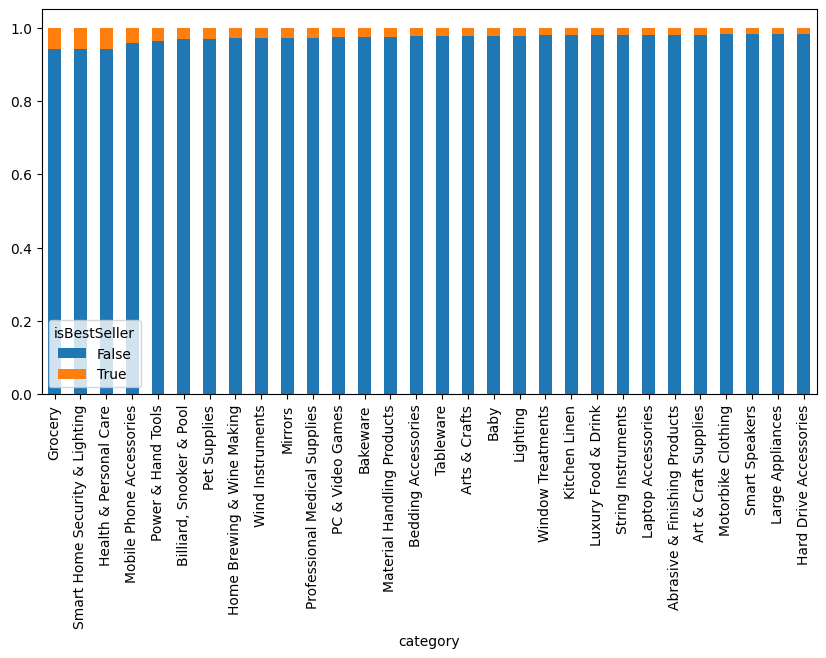

In [45]:
sorted_crosstab_index = pd.crosstab(data.category, data.isBestSeller, normalize="index")[True].sort_values(ascending=False).index
top = sorted_crosstab_index[:30]

filtered_data = data[data["category"].isin(top)]
ct_filtered = pd.crosstab(
    filtered_data.category,
    filtered_data.isBestSeller,
    normalize="index"
)
ct_filtered = ct_filtered.reindex(top)
ct_filtered.plot(kind="bar", stacked=True, figsize=(10,5))

First 30 categories. If I draw all, it is a mess

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

### Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [46]:
Q1 = data.price.quantile(0.25)
Q3 = data.price.quantile(0.75)
IQR = Q3 - Q1
low_value = Q1 - 1.5 * IQR
high_value = Q3 + 1.5 * IQR

condition = (data.price > low_value) & (data.price < high_value)
data_without_outliers = data[condition]

### Violin Plots:

#### Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.




<Axes: xlabel='category', ylabel='price'>

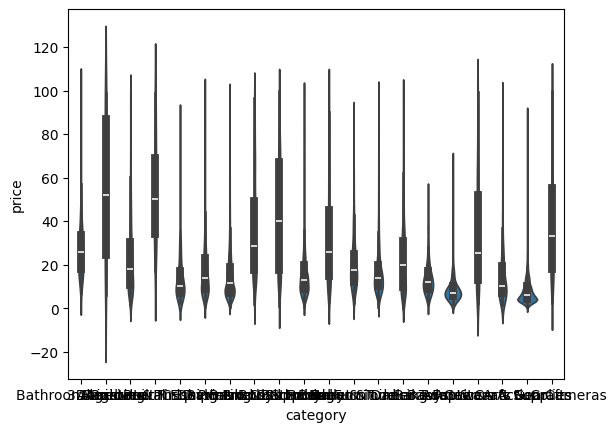

In [ ]:
top_categories = data_without_outliers.groupby("category").size().head(20).index

values = data_without_outliers[data_without_outliers["category"].isin(top_categories)]
sns.violinplot(values, x="category", y="price")

#### Which product category tends to have the highest median price? Don't filter here by top categories.

In [ ]:
data_without_outliers.groupby("category")["price"].median().idxmax()

'Desktop PCs'

### Bar Charts:

#### Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

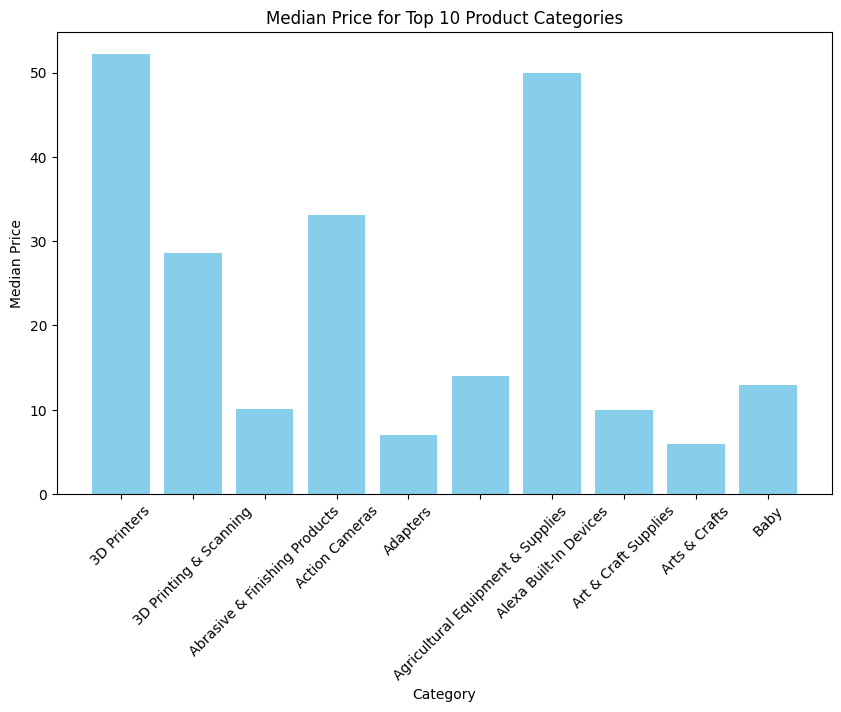

In [59]:
import matplotlib.pyplot as plt

top_categories = data_without_outliers.groupby("category").size().head(10).index

average_price_per_category = data_without_outliers.groupby("category")["price"].median().reset_index()
values = average_price_per_category[average_price_per_category["category"].isin(top_categories)]

plt.figure(figsize=(10, 6))
plt.bar(values["category"], values["price"], color="skyblue")
plt.xlabel("Category")
plt.ylabel("Median Price")
plt.title("Median Price for Top 10 Product Categories")
plt.xticks(rotation=45)
plt.show()

#### Which product category commands the highest average price? Don't filter here by top categories.

In [ ]:
data_without_outliers.groupby("category")["price"].mean().idxmax()

'Desktop PCs'

### Box Plots:

#### Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.


<Axes: xlabel='stars', ylabel='category'>

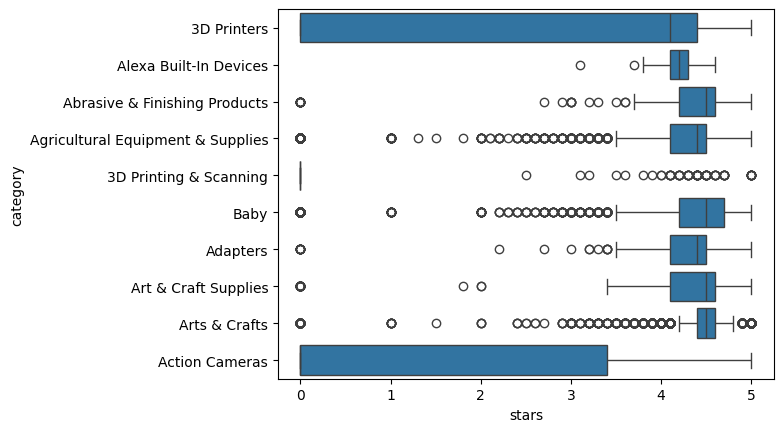

In [65]:
top_categories = data_without_outliers.groupby("category").size().head(10).index

products = data_without_outliers[data_without_outliers["category"].isin(top_categories)]

sns.boxplot(products, x="stars", y="category")


From the previous lab I know that there are a lot of stars = 0.0. Lets remove them and redraw a plot

<Axes: xlabel='stars', ylabel='category'>

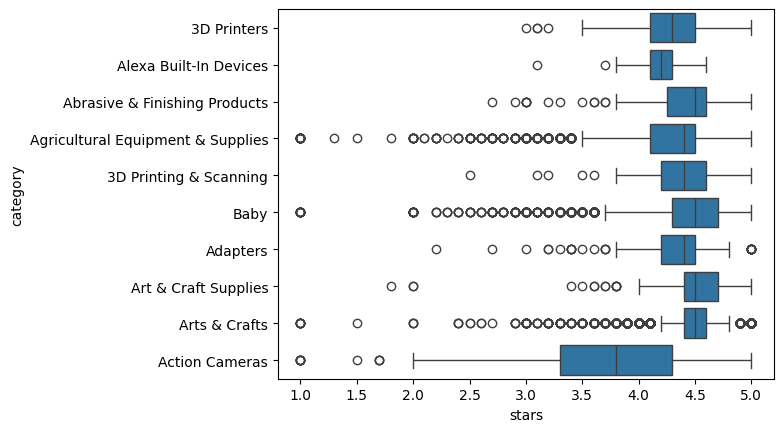

In [66]:
top_categories = data_without_outliers.groupby("category").size().head(10).index

products = data_without_outliers[data_without_outliers["category"].isin(top_categories)]
products = products[products.stars > 0.0]

sns.boxplot(products, x="stars", y="category")

The lowest average rating (from this categories) have Action cameras

### Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [67]:
data_without_outliers.groupby("category")["stars"].median().idxmax()

'Computer Memory'

## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

### Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?




In [70]:
data_without_outliers["price"].corr(data_without_outliers["stars"], method="pearson")

np.float64(-0.0776729987818131)

-0.0777 gives slight negative linear correlation when we include 0 stars

In [71]:
data_without_outliers_with_positive_stars = data_without_outliers[data_without_outliers.stars > 0.0]

data_without_outliers_with_positive_stars.price.corr(data_without_outliers_with_positive_stars.stars, method="pearson")

np.float64(0.006744508067158014)

0.0067 gives slight positive linear correlation when we exclude stars == 0

Looks like there is almost no linear correlation

In [72]:
data_without_outliers["price"].corr(data_without_outliers["stars"], method="spearman")

np.float64(-0.06679697280768324)

In [73]:
data_without_outliers_with_positive_stars = data_without_outliers[data_without_outliers.stars > 0.0]

data_without_outliers_with_positive_stars.price.corr(data_without_outliers_with_positive_stars.stars, method="pearson")

np.float64(0.006744508067158014)

Pretty much the same picture. Almost no monotonic correlation

### Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

<Axes: xlabel='price', ylabel='stars'>

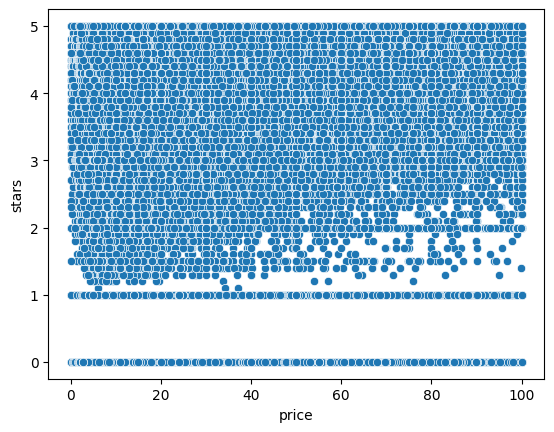

In [76]:
sns.scatterplot(y=data_without_outliers["stars"], x=data_without_outliers["price"])

<Axes: xlabel='price', ylabel='stars'>

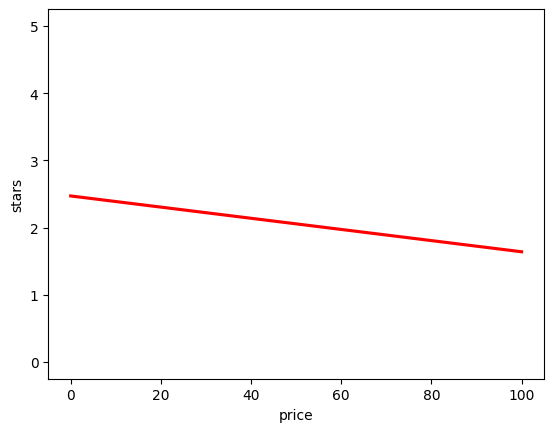

In [82]:
sns.regplot(y=data_without_outliers["stars"], x=data_without_outliers["price"], scatter_kws={"s": 0}, line_kws={"color": "red"})

There is a negative correlation. As price goes higher the rating goes down. BUT IT IS WITH RATING 0.0! There are fewer purchases for such products hence lets calculate once again without 0.0

<Axes: xlabel='price', ylabel='stars'>

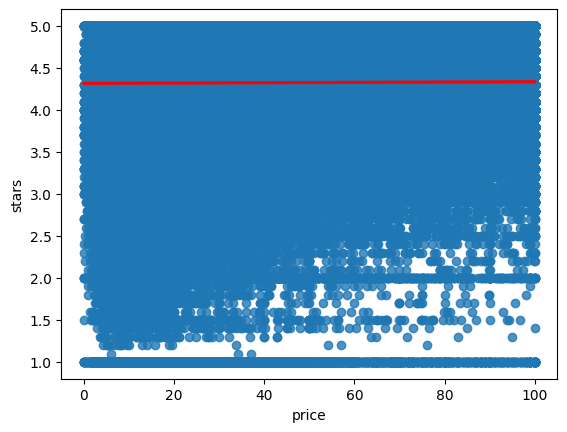

In [83]:
sns.regplot(y=data_without_outliers_with_positive_stars["stars"], x=data_without_outliers_with_positive_stars["price"], line_kws={"color": "red"})

<Axes: xlabel='price', ylabel='stars'>

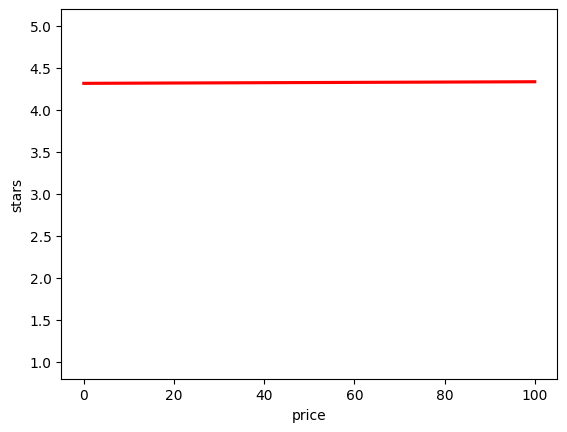

In [80]:
sns.regplot(y=data_without_outliers_with_positive_stars["stars"], x=data_without_outliers_with_positive_stars["price"], scatter_kws={"s": 0}, line_kws={"color": "red"})

Even though there is visually some correlation on scatter plot, when we draw regression line, the it has almost 0 angle 

### Use a correlation heatmap to visualize correlations between all numerical variables.

In [116]:
numerical_columns = ["stars", "reviews", "price", "boughtInLastMonth"]
data_without_outliers.head()



,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


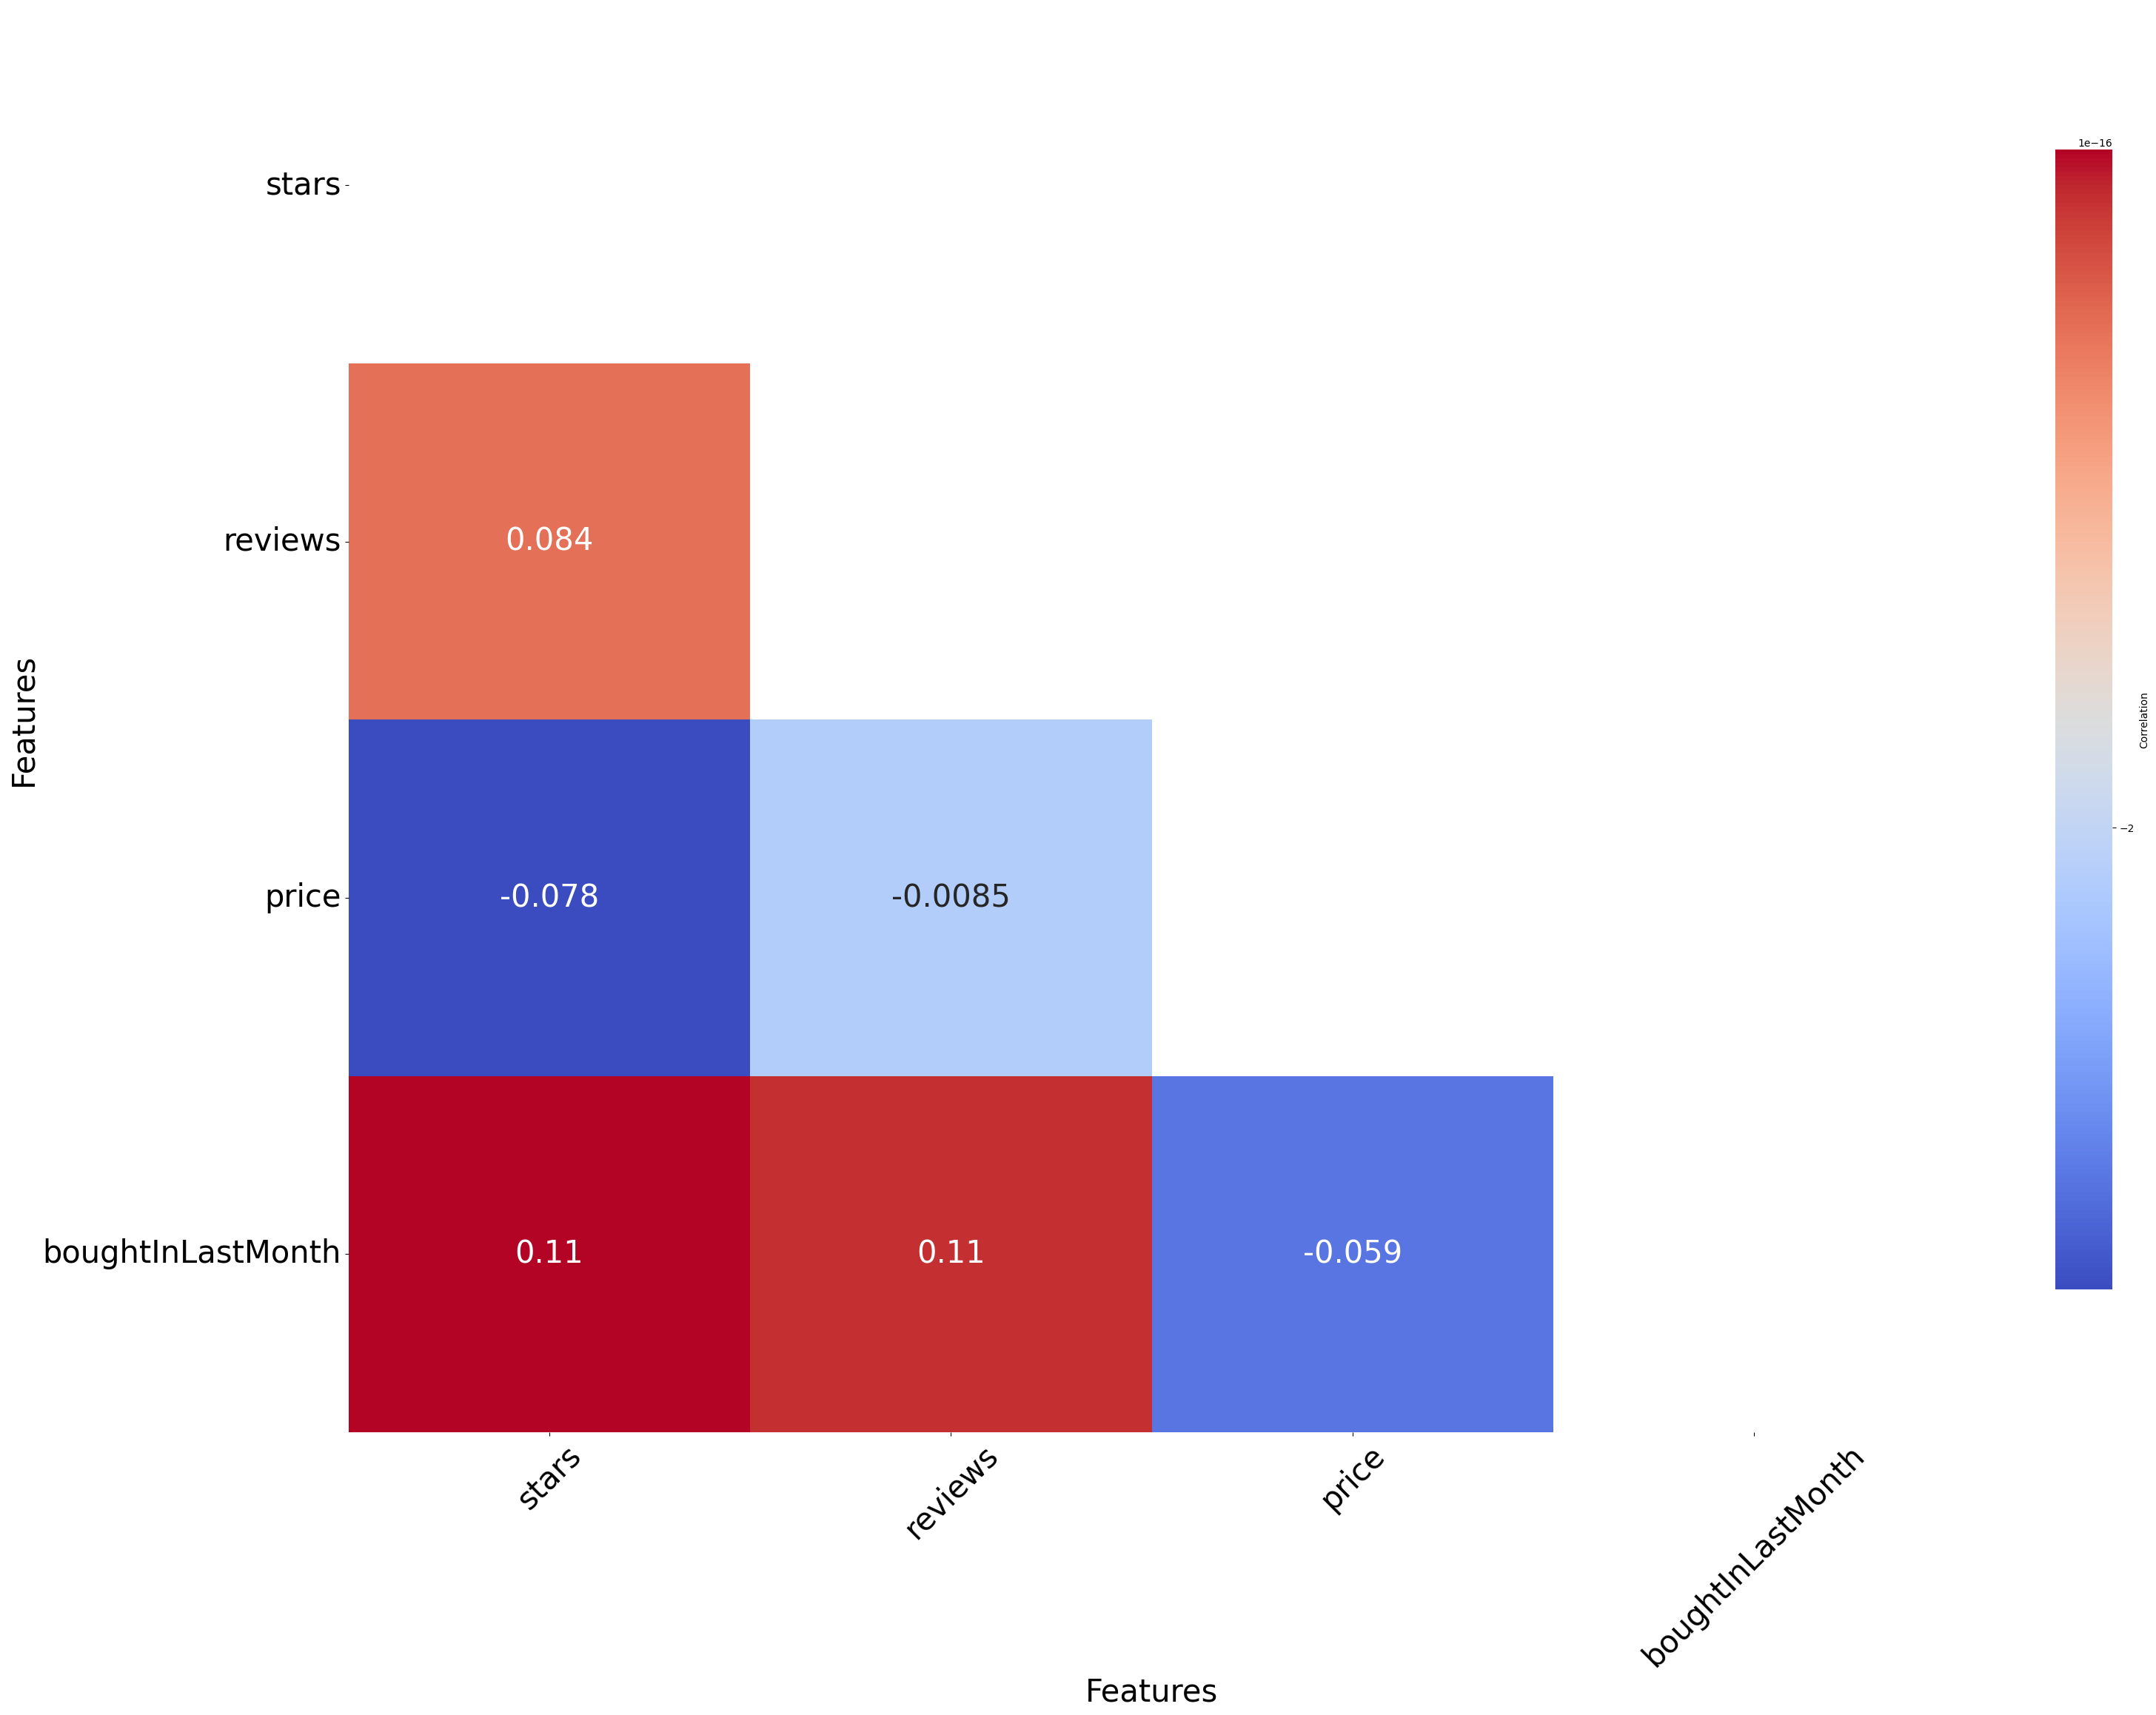

In [123]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Example correlation heatmap
correlation_matrix = data_without_outliers[numerical_columns].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(35, 25))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    annot_kws={"size": 30},   # size of numbers inside the squares
    cbar_kws={"label": "Correlation", "shrink": 0.8, "ticks": np.arange(-1, 1.1, 0.2)}
)

# Axis labels
plt.xlabel("Features", fontsize=30)
plt.ylabel("Features", fontsize=30)

# Tick labels
plt.xticks(fontsize=30, rotation=45)
plt.yticks(fontsize=30, rotation=0)

plt.show()

There is some positive correlation between stars, reviews and boughInLastMonth. And there is positive correlation between reviews and stars, because there is a lot of 0.0 stars in table with 0 reviews. But when people write review it brights the rating higher

Now without ration 0.0

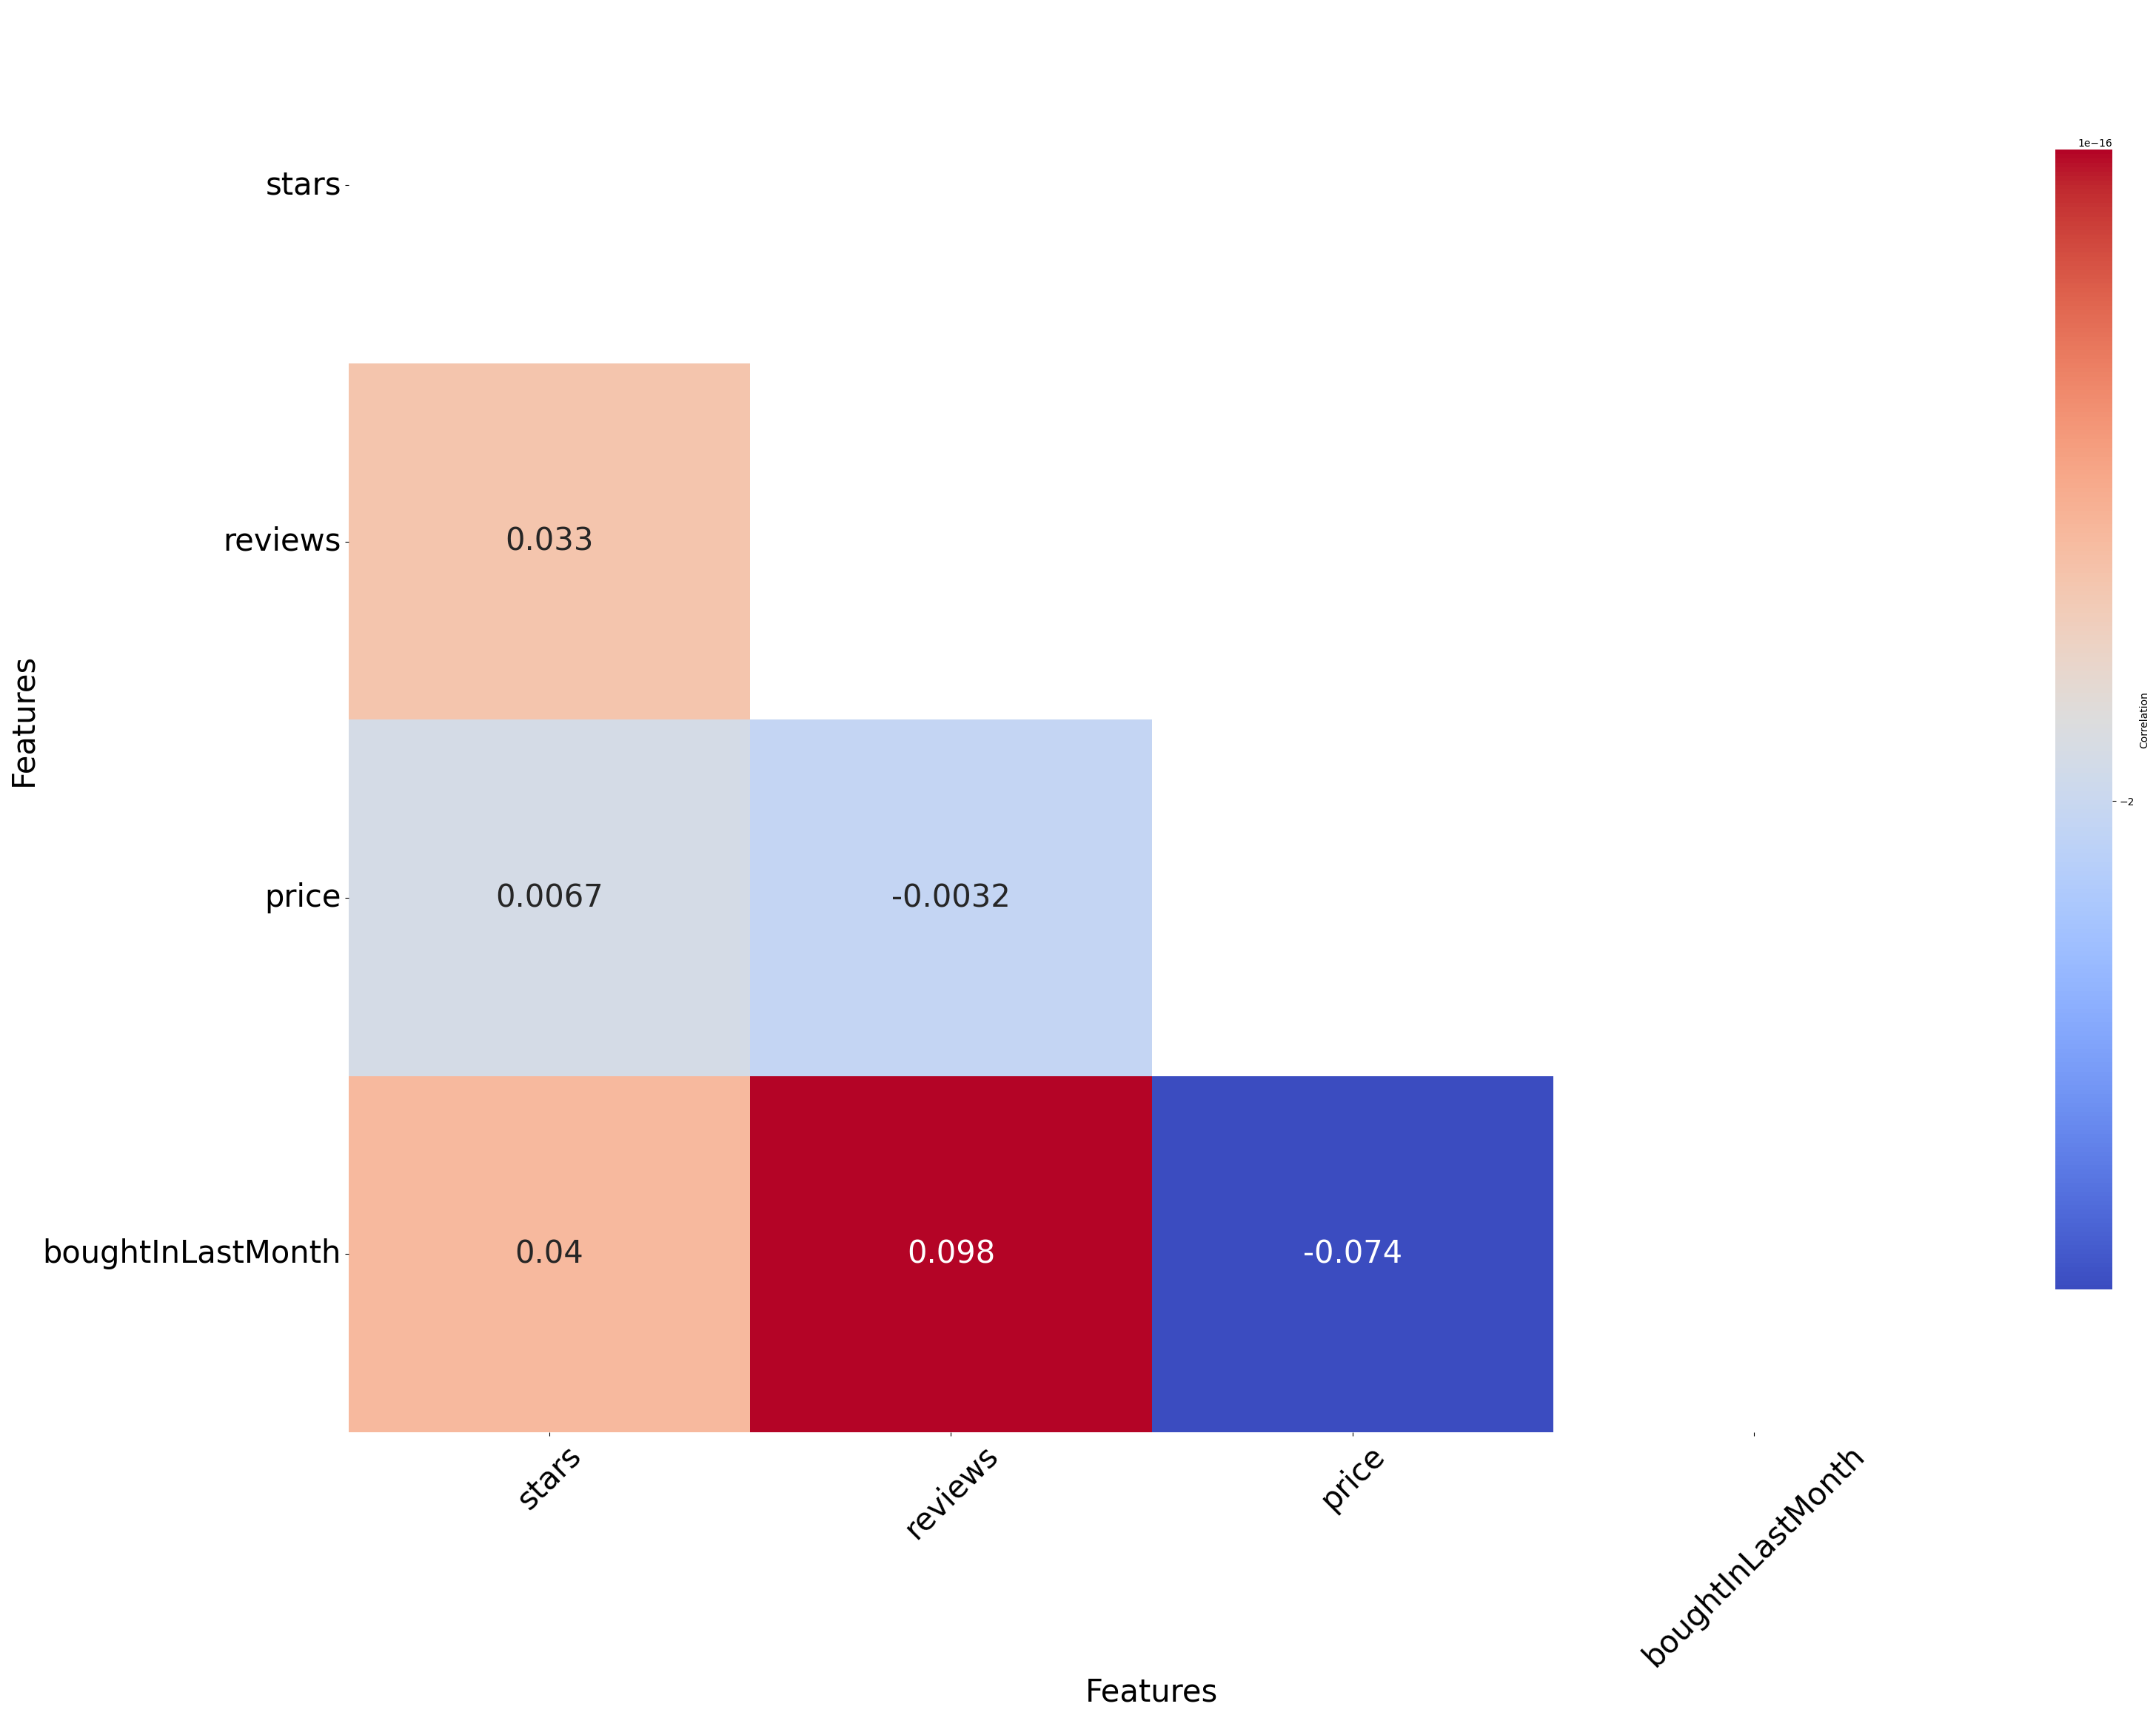

In [124]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Example correlation heatmap
correlation_matrix = data_without_outliers_with_positive_stars[numerical_columns].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(35, 25))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    annot_kws={"size": 30},   # size of numbers inside the squares
    cbar_kws={"label": "Correlation", "shrink": 0.8, "ticks": np.arange(-1, 1.1, 0.2)}
)

# Axis labels
plt.xlabel("Features", fontsize=30)
plt.ylabel("Features", fontsize=30)

# Tick labels
plt.xticks(fontsize=30, rotation=45)
plt.yticks(fontsize=30, rotation=0)

plt.show()

There is a some positive correlation between the reviews and boughtInLastMonth. As people boought more of the product, the number of reviews grow

There is some negative correlation between price and boughtInLastMonth. As people buy more of the product the price of purchase decreases. People buy more cheap products. Expected

### Examine if product prices typically follow a normal distribution using a QQ plot.

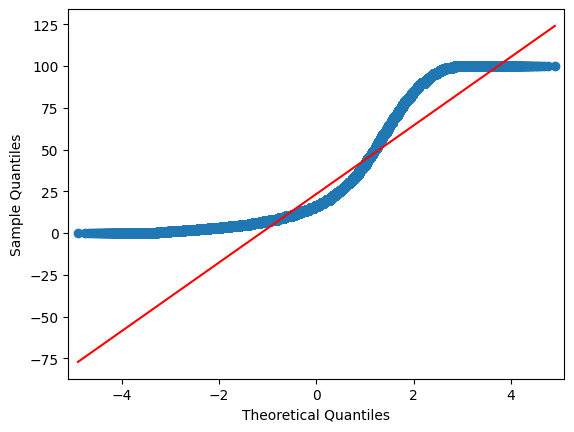

In [ ]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(data_without_outliers['price'], line='s')

Very not normal distribution!

### Submission: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.

## Bonus:

Do the same analysis without taking out the outliers. What are your insights?

### Violin Plots:

#### Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.




<Axes: xlabel='category', ylabel='price'>

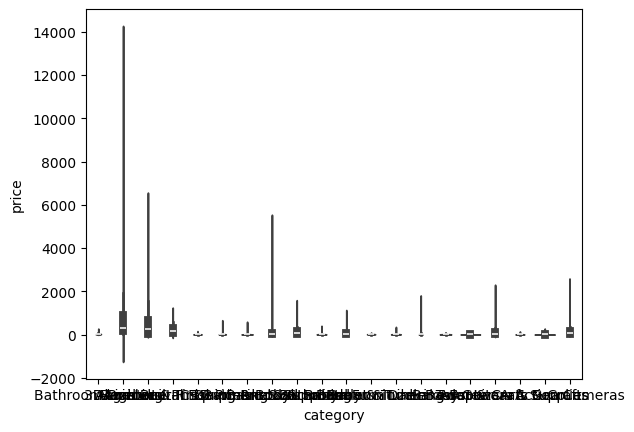

In [84]:
top_categories = data.groupby("category").size().head(20).index

values = data[data["category"].isin(top_categories)]
sns.violinplot(values, x="category", y="price")

<Axes: xlabel='category', ylabel='price'>

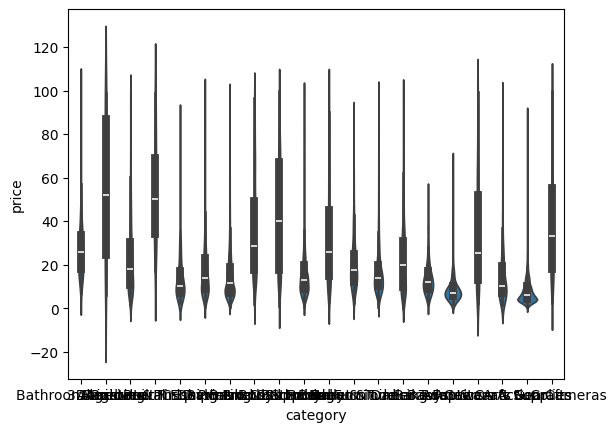

In [85]:
top_categories = data_without_outliers.groupby("category").size().head(20).index

values = data_without_outliers[data_without_outliers["category"].isin(top_categories)]
sns.violinplot(values, x="category", y="price")

Outliers make the already hard to see plot very unreadable

#### Which product category tends to have the highest median price? Don't filter here by top categories.

In [86]:
data.groupby("category")["price"].median().idxmax()

'Laptops'

without outliers we had different result (Desktop PC). It means that there are very expencive laptops out there

### Bar Charts:

#### Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

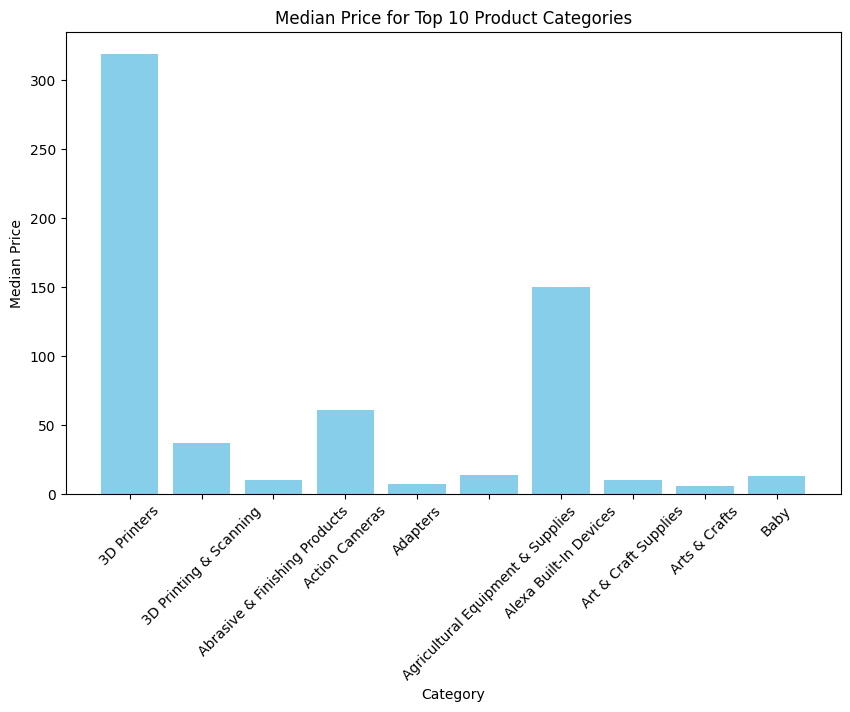

In [87]:
import matplotlib.pyplot as plt

top_categories = data.groupby("category").size().head(10).index

average_price_per_category = data.groupby("category")["price"].median().reset_index()
values = average_price_per_category[average_price_per_category["category"].isin(top_categories)]

plt.figure(figsize=(10, 6))
plt.bar(values["category"], values["price"], color="skyblue")
plt.xlabel("Category")
plt.ylabel("Median Price")
plt.title("Median Price for Top 10 Product Categories")
plt.xticks(rotation=45)
plt.show()

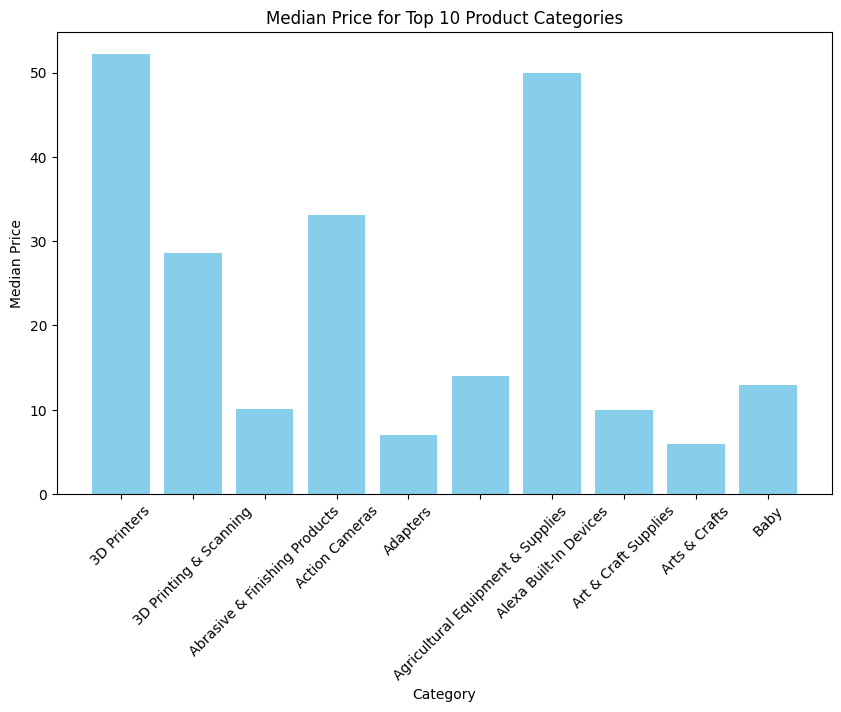

In [88]:
import matplotlib.pyplot as plt

top_categories = data_without_outliers.groupby("category").size().head(10).index

average_price_per_category = data_without_outliers.groupby("category")["price"].median().reset_index()
values = average_price_per_category[average_price_per_category["category"].isin(top_categories)]

plt.figure(figsize=(10, 6))
plt.bar(values["category"], values["price"], color="skyblue")
plt.xlabel("Category")
plt.ylabel("Median Price")
plt.title("Median Price for Top 10 Product Categories")
plt.xticks(rotation=45)
plt.show()

The difference between categories increase

#### Which product category commands the highest average price? Don't filter here by top categories.

In [ ]:
data.groupby("category")["price"].mean().idxmax()

'Laptops'

Again the answer changed from 'Desktop PCs' to Laptops

### Box Plots:

#### Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.


<Axes: xlabel='stars', ylabel='category'>

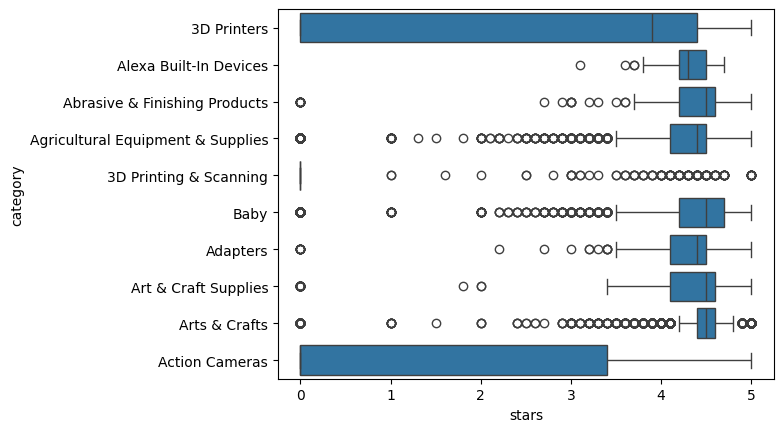

In [92]:
top_categories = data.groupby("category").size().head(10).index

products = data[data["category"].isin(top_categories)]

sns.boxplot(products, x="stars", y="category")


<Axes: xlabel='stars', ylabel='category'>

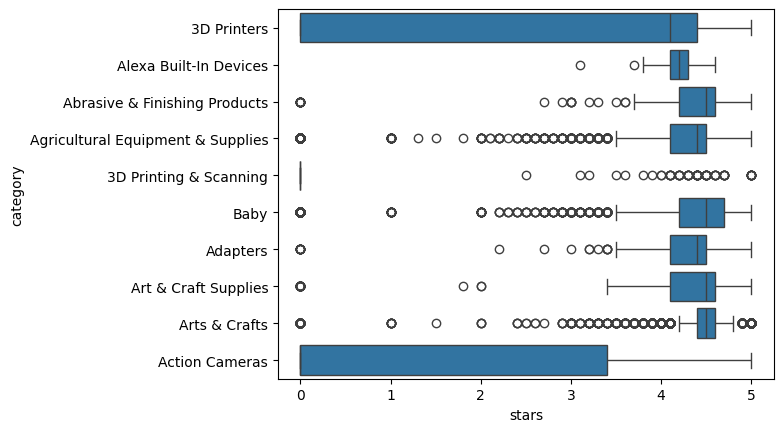

In [93]:
top_categories = data_without_outliers.groupby("category").size().head(10).index

products = data_without_outliers[data_without_outliers["category"].isin(top_categories)]

sns.boxplot(products, x="stars", y="category")


There is no significant difference with and without outliers

From the previous lab I know that there are a lot of stars = 0.0. Lets remove them and redraw a plot

<Axes: xlabel='stars', ylabel='category'>

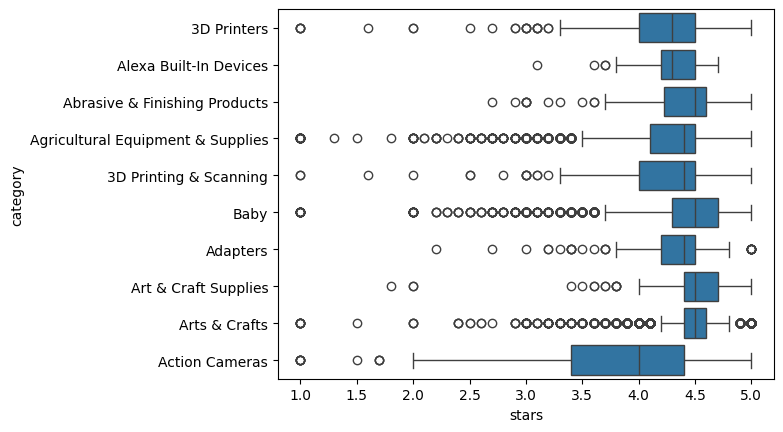

In [94]:
top_categories = data.groupby("category").size().head(10).index

products = data[data["category"].isin(top_categories)]
products = products[products.stars > 0.0]

sns.boxplot(products, x="stars", y="category")

<Axes: xlabel='stars', ylabel='category'>

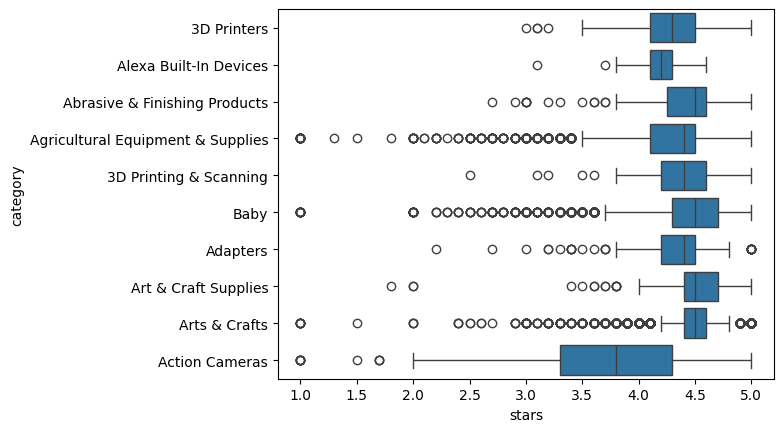

In [95]:
top_categories = data_without_outliers.groupby("category").size().head(10).index

products = data_without_outliers[data_without_outliers["category"].isin(top_categories)]
products = products[products.stars > 0.0]

sns.boxplot(products, x="stars", y="category")

I see a very slight difference, and of course there are more outliers on the plot

### Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [96]:
data.groupby("category")["stars"].median().idxmax()

'Computer Memory'

The same

## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

### Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?




In [97]:
data["price"].corr(data["stars"], method="pearson")

np.float64(-0.12490673262148537)

Now there is bigger negative linear coeff -0.125, comparing to previous -0.777

In [98]:
data = data[data.stars > 0.0]

data.price.corr(data.stars, method="pearson")

np.float64(-0.00491182300075293)

Now there is almost 0, but still negative (-0.0049) instead of positive (0.0067) linear correlation. 

In [101]:
data["price"].corr(data["stars"], method="spearman")

np.float64(0.020035042659527894)

Old value negative -0.06679697280768324

New value positive 0.020035042659527894

Both are close to 0

In [102]:
data = data[data.stars > 0.0]

data.price.corr(data.stars, method="pearson")

np.float64(-0.00491182300075293)

Old value positive 0.006744508067158014

New value -0.00491182300075293

Almost no monotonic correlation

### Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

<Axes: xlabel='price', ylabel='stars'>

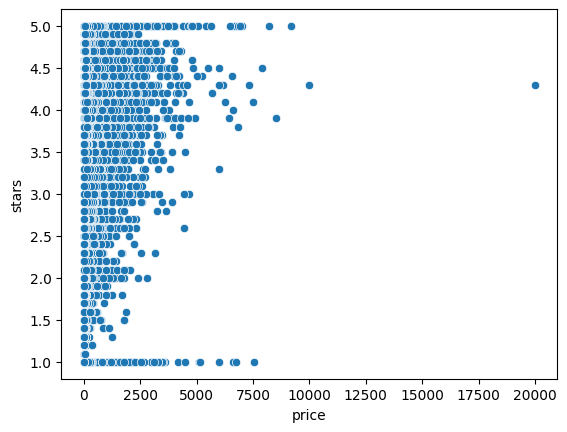

In [103]:
sns.scatterplot(y=data["stars"], x=data["price"])

There is a big outlier. One item for 20000 with 4.4 rating

<Axes: xlabel='price', ylabel='stars'>

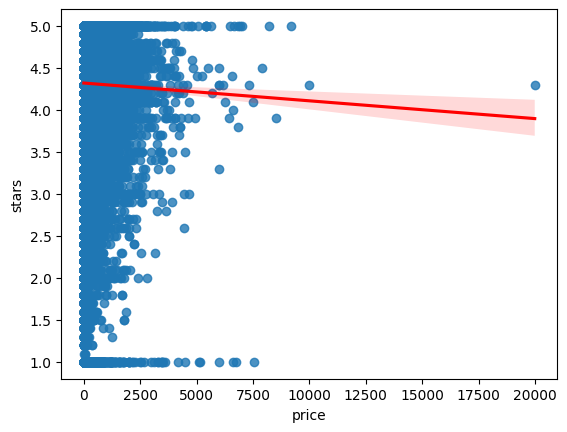

In [106]:
sns.regplot(y=data["stars"], x=data["price"], line_kws={"color": "red"})

# Conclusion
ensure the summary synthesizes results into specific recommendations or next steps for business, even if brief. 

I would suggest to do analysis between the boughtInLastMonth and the stars. Because the end goal is to sell more items, but right now there are a lot of items without rating in general. If there is a correlation then we need to work more with 0.0 rating items. Maybe the Aliexpress model, where if the user doesnt leave the review themself, the systems sets 5.0 review. It is controversial, but one way to think about it is that people are good at leaving negative reviews and bad at leaving good reviews. 

However the last statement kind of disproved by the statistics, because on average people leave 4.5 stars. So auto 5.0 will probably skew the statistics even more to 5.0.

Looks like there are some amount of items with price 0.0, which is not possible. I would spend additional time analysing what are the items, and why is 0.0 price. The same goes for the items with extreme prices.